# Project Idea: Multilingual Sentiment Analysis Using XLM-RoBERTa

### 1. Introduction

The aim of this project is to develop a **Multilingual Sentiment Analysis System** that can analyze text written in both Arabic and English and automatically classify its sentiment into three categories: **Positive, Negative, and Neutral**.

The project focuses on building a single deep learning model capable of understanding sentiment in two different languages rather than developing a separate model for each language. It uses a multilingual transformer architecture called **XLM-RoBERTa (XLM-R)**, which is pretrained on multiple languages and can capture contextual information from text.

### 2. Datasets

The project uses two different datasets:

- **Arabic Dataset:** An Arabic sentiment reviews dataset containing positive and negative reviews.
- **English Dataset:** A Twitter sentiment analysis dataset containing tweets classified as Positive, Negative, Neutral, and Irrelevant.

Both datasets are explored, cleaned, and prepared before being combined into one unified dataset.

The Irrelevant category is removed from the English dataset because the project focuses on sentiment classification.

### 3. Data Preprocessing and Integration

The Arabic and English datasets undergo preprocessing to prepare the text for model training.

The preprocessing includes:
- Checking and handling missing values.
- Removing duplicate records.
- Cleaning text by removing URLs and user mentions.
- Standardizing sentiment labels.
- Converting text and other features into appropriate data types.
- Removing empty text entries.

The sentiment labels are unified into three classes:

| Label | Sentiment |
|---|---|
| 0 | Negative |
| 1 | Neutral |
| 2 | Positive |

Since the Arabic dataset contains only positive and negative reviews, it does not provide neutral examples. The English dataset provides examples for all three categories.

After preprocessing, both datasets are combined into a single dataset while preserving the language information.

### 4. Model Development

The project uses **XLM-RoBERTa (XLM-R)** as the main classification model.

XLM-R is a multilingual transformer model that can process Arabic and English text. It is fine-tuned on the combined dataset to learn the contextual patterns and linguistic features associated with different sentiment categories.

The model receives the entity and text as input and predicts one of the three sentiment classes.

### 5. Model Training

The combined dataset is divided into training, validation, and testing sets.

The model is fine-tuned using the Hugging Face Transformers library and PyTorch.

To address class imbalance, class weights are calculated and incorporated into the loss function through a custom Weighted Trainer. This helps the model account for differences in the number of examples belonging to each sentiment class.

Early stopping is also implemented to help prevent unnecessary training and select the best-performing model.

### 6. Model Evaluation

After training, the model is evaluated using the test dataset to measure its performance.

The evaluation includes:

- Accuracy.
- Weighted F1-score.
- Confusion Matrix.
- Classification Report.
- Arabic-specific evaluation.
- English-specific evaluation.
- Analysis of incorrectly classified examples.

Training and validation performance are also visualized using accuracy, F1-score, and loss curves.

### 7. Model Saving and Prediction

After completing training and evaluation, the final fine-tuned model and tokenizer are saved for future use.

A prediction function is implemented to allow users to enter new Arabic or English sentences and receive:

- Predicted sentiment.
- Prediction confidence score.

An additional advanced prediction function is developed to handle uncertain and mixed sentiment predictions using confidence thresholds and decision rules.

### 8. Final Objective

The ultimate objective of this project is to build a unified Arabic-English sentiment analysis system that can understand text in both languages and automatically identify whether an expressed opinion is **Positive, Negative, or Neutral**.

The system demonstrates how multilingual transformer models can be fine-tuned to perform sentiment classification across different languages using a shared model.

In [1]:
!pip install transformers torch scikit-learn datasets

## 1. Import Libraries

In [2]:
# load libraries
import os
import re
import nltk
import torch
import string
import warnings

import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

from datasets import Dataset
from sklearn.metrics import *
from collections import Counter
from wordcloud import WordCloud
from transformers import Trainer
from nltk.corpus import stopwords

from nltk.stem import SnowballStemmer
from nltk.stem.isri import ISRIStemmer
from nltk.tokenize import word_tokenize
from transformers import TrainingArguments
from transformers import EarlyStoppingCallback

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments


# download nltk tool
nltk.download('stopwords')
nltk.download('punkt')


stop_words_en = set(stopwords.words('english'))
stop_words_ar = set(stopwords.words('arabic'))

# for merge dataset
stop_words = stop_words_en.union(stop_words_ar)

# Stemmer for two langs
stemmer = SnowballStemmer('english')
arabic_stemmer = ISRIStemmer()

# Set plot style
plt.style.use('seaborn-v0_8-colorblind')
sns.set_palette('husl')

# seed
np.random.seed(42)

# filter warnings
warnings.filterwarnings('ignore')

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


## 2. Arabic Dataset Loading and Exploration

In [3]:
# load arbic dataset 
arabic_path = "/kaggle/input/datasets/abdallaellaithy/330k-arabic-sentiment-reviews/arabic_sentiment_reviews.csv"
data_ar = pd.read_csv(arabic_path, nrows=80000)


df_ar = data_ar.copy()
df_ar.head()

# Information of data
print(f'\n\nInFo of AR:\n {df_ar.info()}\n\n')
# check misss values
print(f'Missing Value of AR:\n {df_ar.isna().sum()}')

# Check duplicated
print(f'Number of Duplicates Arabic Data:\n {df_ar.duplicated().sum()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    80000 non-null  int64 
 1   content  80000 non-null  object
dtypes: int64(1), object(1)
memory usage: 1.2+ MB


InFo of AR:
 None


Missing Value of AR:
 label      0
content    0
dtype: int64
Number of Duplicates Arabic Data:
 8


In [4]:
# Remove Duplicated
df_ar.drop_duplicates(inplace=True)

print(f'Number of Duplicates Arabic Data: {df_ar.duplicated().sum()}')

Number of Duplicates Arabic Data: 0


In [5]:
sentiment_mapping = {0: 'Negative', 1:'Positive'}
df_ar['Polarity'] = df_ar['label'].map(sentiment_mapping)

df_ar.tail()

,label,content,Polarity
79995,1,تريد العضلة ذات الرأسين الكبيرة؟ابدأ بالذهول !...,Positive
79996,0,مشكلات الشحن: اضطررت أيضًا إلى إعادة إرسال Mor...,Negative
79997,1,أداة رائعة لإضافتها إلى متجرك: تم استلام آلة د...,Positive
79998,1,مقاعد البدلاء Top Mortiser: لقد كنت قلقًا بشأن...,Positive
79999,1,نفس قضايا UPS القديمة: وصل الصندوق في الغالب.ع...,Positive


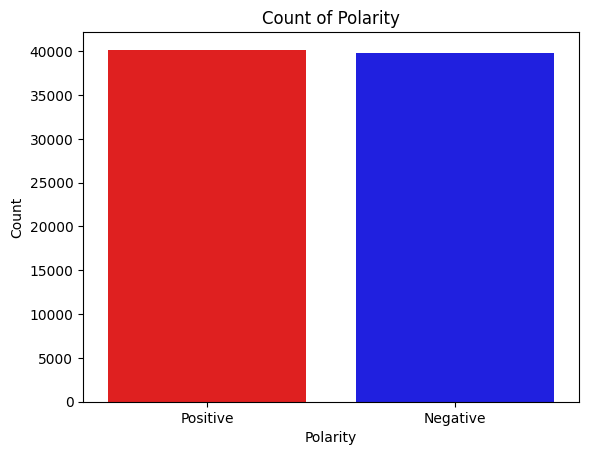

In [6]:
# Counter of sentiment 
COLORS = ['red', 'blue']
sns.countplot(df_ar, x= 'Polarity', palette= COLORS)

plt.xlabel("Polarity")
plt.ylabel("Count")
plt.title("Count of Polarity")

plt.show()

## 3. Arabic Text Preprocessing

In [7]:
def preprocess_ar_light(text):
    text = str(text)

    # remove links
    text = re.sub(r'http\S+|www\S+', '', text)

    # remove mentions
    text = re.sub(r'@\w+', '', text)
    
    # remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

df_ar["content"] = df_ar["content"].apply(lambda x: preprocess_ar_light(x))
df_ar.head()

,label,content,Polarity
0,1,النعال المريحة: أرتدي هذه النعال كثيرًا!فهي دا...,Positive
1,1,منتج جميل ، خدمة سيئة: لقد اشتريت زوجًا من الن...,Positive
2,1,جيد للأشياء الصغيرة: هذا يعمل بشكل جيد لالتقاط...,Positive
3,0,واهية للغاية: flimsyif للغاية ، فأنت تشتريه ، ...,Negative
4,1,Pop for Girls and Girly Boys ، والأشخاص الذين ...,Positive


## 4. Arabic Word Frequency Analysis

In [8]:
# count word accurences 
word_count = Counter(' '.join(df_ar['content']).split())

# convert to dataframe
words_df = pd.DataFrame(list(word_count.items()), columns= ['words', 'Frequency'])

# sort dataframe
words_df = words_df.sort_values(by='Frequency',
                                ascending=False).reset_index(drop= True)

words_df.insert(0, 'Rank', words_df.index+1)
words_df.head()

,Rank,words,Frequency
0,1,،,243330
1,2,من,155020
2,3,في,123515
3,4,هذا,87458
4,5,على,87310


### Show Top Words of Each Label

In [9]:
def show_top_words(input, type):
    words = input.split()
    top_words = pd.DataFrame(Counter(words).most_common(25), columns=['Term', 'Count'])
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(12, 10))
    sns.barplot(x='Count', y='Term', data=top_words, palette='coolwarm')
    plt.title(f"Top 25 Words in {type} Reviews")
    plt.xlabel("Occurrences")
    plt.ylabel("Terms")
    plt.tight_layout()
    plt.show()

### Positive words

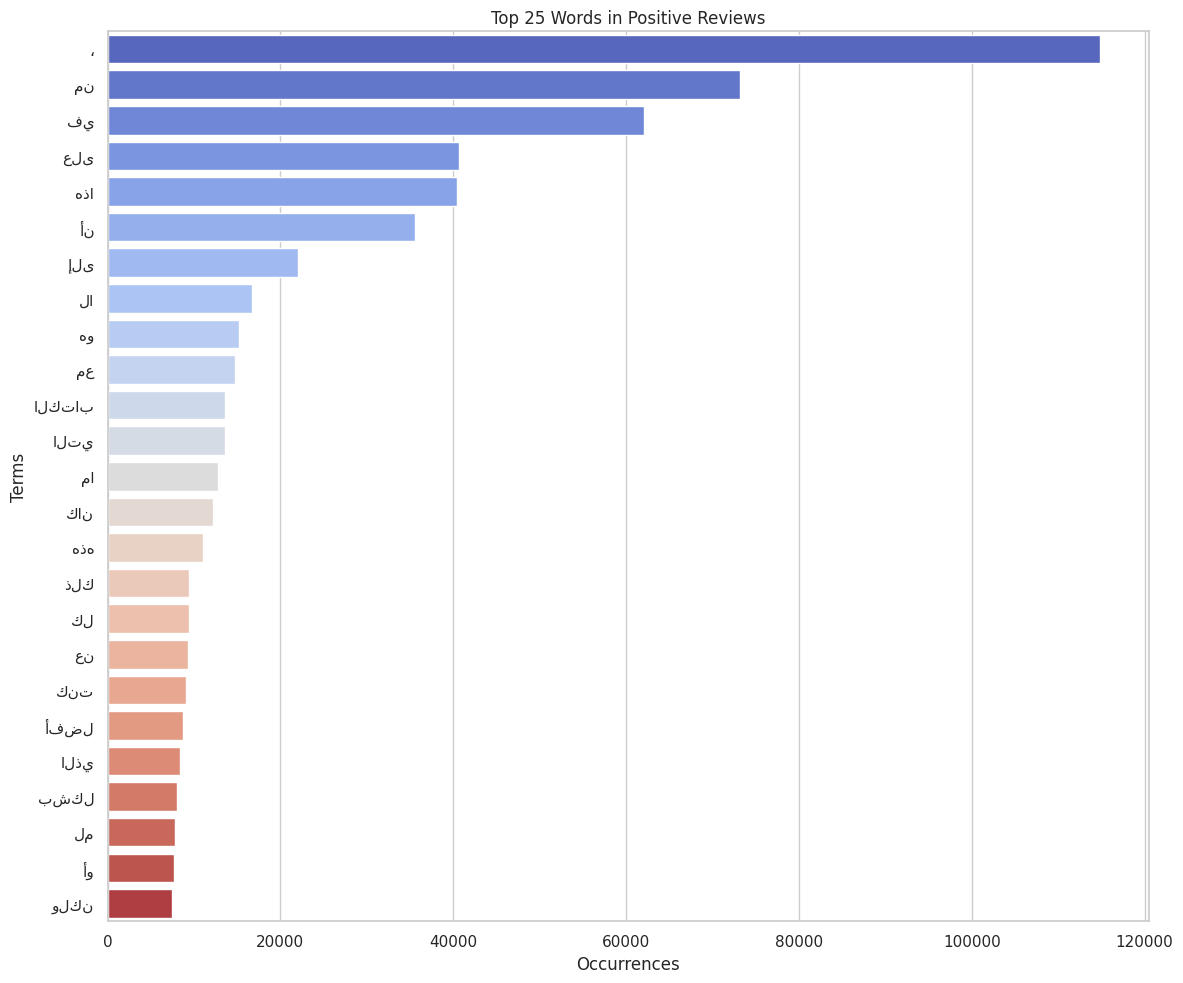

In [10]:
# show frequancy of positive words
positive_words = ' '.join(df_ar[df_ar['label'] == 1]['content'])

show_top_words(positive_words, "Positive")

### Negative Words

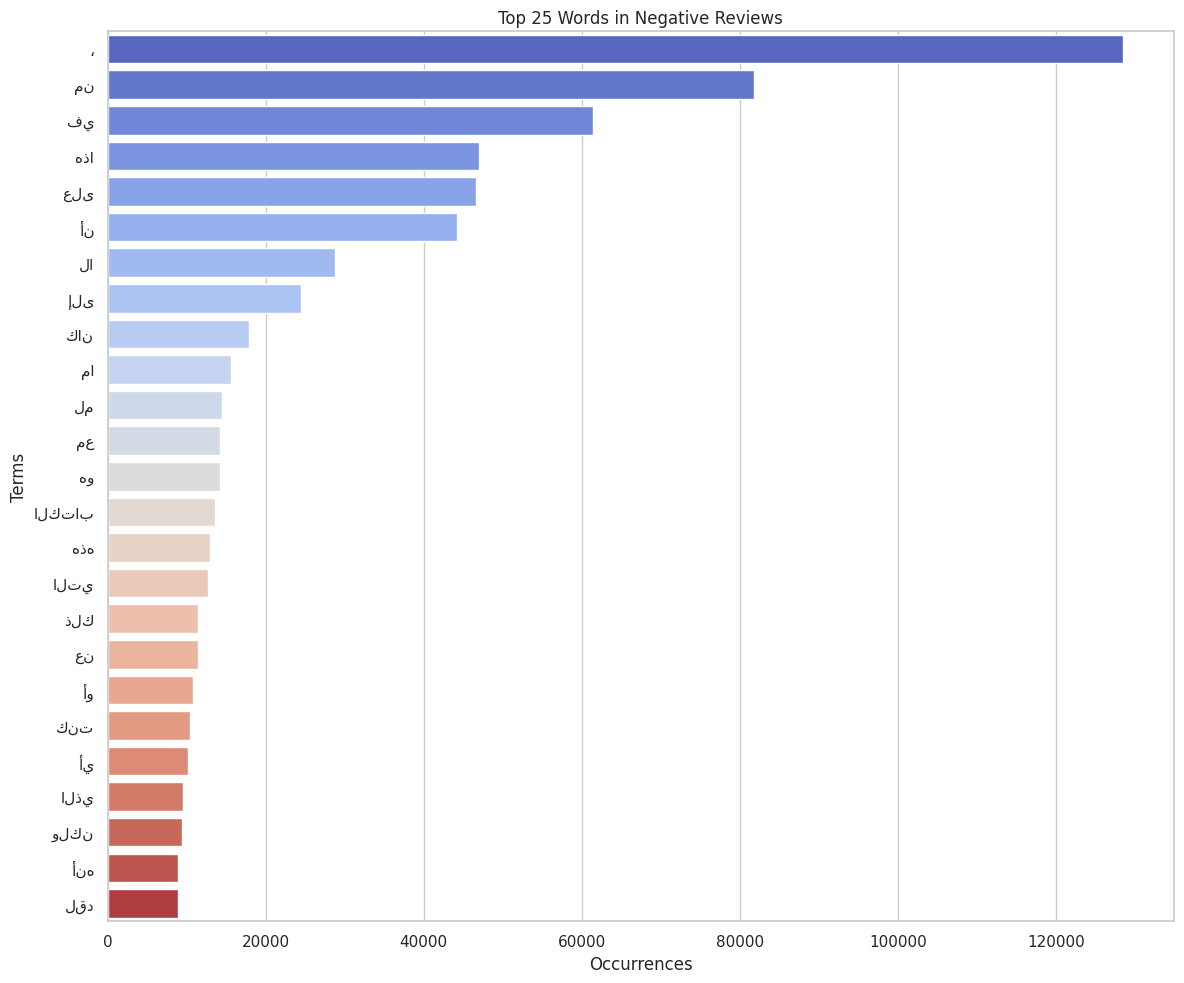

In [11]:
# show frequancy of positive words
Negative_words = ' '.join(df_ar[df_ar['label'] == 0]['content'])

show_top_words(Negative_words, "Negative")

## 5. English Dataset Loading and Exploration

In [12]:
en_path = "/kaggle/input/datasets/jp797498e/twitter-entity-sentiment-analysis/twitter_training.csv"
data_en = pd.read_csv(en_path, header= None)
data_en.head()

,0,1,2,3
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [13]:
# copy dataset 
df_en = data_en.copy()
df_en.head(3)

# Rename columns
df_en.columns = ['id', 'game', 'sentiment', 'text']

print(f"New columns: \n{df_en.columns}")

# check missing value
print(f'Missing Value: {df_en.isnull().sum()}')

New columns: 
Index(['id', 'game', 'sentiment', 'text'], dtype='object')
Missing Value: id             0
game           0
sentiment      0
text         686
dtype: int64


In [14]:
# clean missing vals
df_en = df_en.dropna(subset=['text', 'sentiment'])

df_en.isnull().sum()

id           0
game         0
sentiment    0
text         0
dtype: int64

In [15]:
print(f"\nEnglish Data Information:\n {df_en.info()}\n\n")

# check of duplicated
print(f'Number of Duplicated {df_en.duplicated().sum()}')

<class 'pandas.core.frame.DataFrame'>
Index: 73996 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         73996 non-null  int64 
 1   game       73996 non-null  object
 2   sentiment  73996 non-null  object
 3   text       73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.8+ MB

English Data Information:
 None


Number of Duplicated 2340


In [16]:
# Drop Duplicated values
df_en.drop_duplicates(inplace=True)
df_en.duplicated().sum()

np.int64(0)

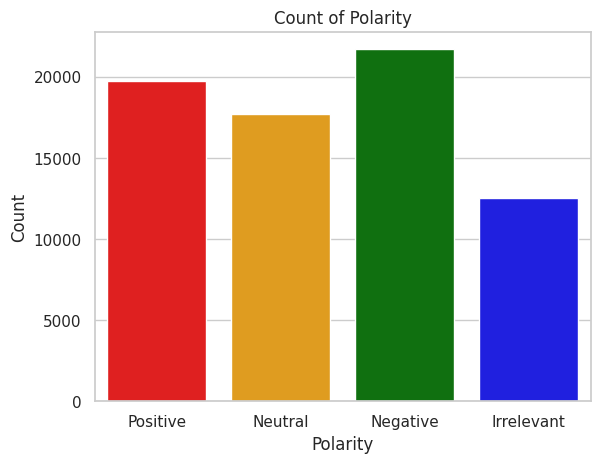

In [17]:
# Counter of sentiment 
COLORS = ['red', 'orange', 'green', 'blue']
sns.countplot(df_en, x= 'sentiment', palette= COLORS)

plt.xlabel("Polarity")
plt.ylabel("Count")
plt.title("Count of Polarity")

plt.show()

### Punctuation in English language

<details>
<summary>Click Here for Code</summary> </br>

```python
# Punctuation
print(f'Punctuation in en: {string.punctuation}')

## 6. English Text Preprocessing

In [18]:
def preprocess_en_light(text):
    text = str(text).lower()

    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)

    return text.strip()

In [19]:
print(f'Sample of Data\n\n {df_en['text'][:5]}\n\n')
print('-'*100)

df_en['text'] = df_en['text'].apply(preprocess_en_light)

df_en['text'][:5]

Sample of Data

 0    im getting on borderlands and i will murder yo...
1    I am coming to the borders and I will kill you...
2    im getting on borderlands and i will kill you ...
3    im coming on borderlands and i will murder you...
4    im getting on borderlands 2 and i will murder ...
Name: text, dtype: object


----------------------------------------------------------------------------------------------------


0    im getting on borderlands and i will murder yo...
1    i am coming to the borders and i will kill you...
2    im getting on borderlands and i will kill you ...
3    im coming on borderlands and i will murder you...
4    im getting on borderlands 2 and i will murder ...
Name: text, dtype: object

## 7. English Sentiment Visualization

In [20]:
# count word accurences 
word_count = Counter(' '.join(df_en['text']).split())

# convert to dataframe
words_df = pd.DataFrame(list(word_count.items()), columns= ['words', 'Frequency'])

# sort dataframe
words_df = words_df.sort_values(by='Frequency',
                                ascending=False).reset_index(drop= True)

words_df.insert(0, 'Rank', words_df.index+1)
words_df.head()

,Rank,words,Frequency
0,1,the,43548
1,2,i,28327
2,3,to,28274
3,4,and,26015
4,5,a,23636


In [21]:
def generate_wordcloud(text_input, title=""):
    cloud = WordCloud(width=1500, height=800, max_words= 500,
                      background_color='black', colormap="coolwarm")
    WORDCOLUD = cloud.generate(text_input)

    plt.figure(figsize=(10,8))
    plt.imshow(WORDCOLUD, interpolation='bilinear')
    plt.axis('off')

    plt.title(title, fontsize=20)
    plt.tight_layout()
    plt.show()
    

In [22]:
df_en = df_en[df_en['sentiment'].str.lower() != 'irrelevant']

sentiment_mapping = {'Negative':0, 'Neutral': 1, 'Positive': 2}
df_en['sentiment'] = df_en['sentiment'].map(sentiment_mapping)

df_en.head()

,id,game,sentiment,text
0,2401,Borderlands,2,im getting on borderlands and i will murder yo...
1,2401,Borderlands,2,i am coming to the borders and i will kill you...
2,2401,Borderlands,2,im getting on borderlands and i will kill you ...
3,2401,Borderlands,2,im coming on borderlands and i will murder you...
4,2401,Borderlands,2,im getting on borderlands 2 and i will murder ...


### Positive Words

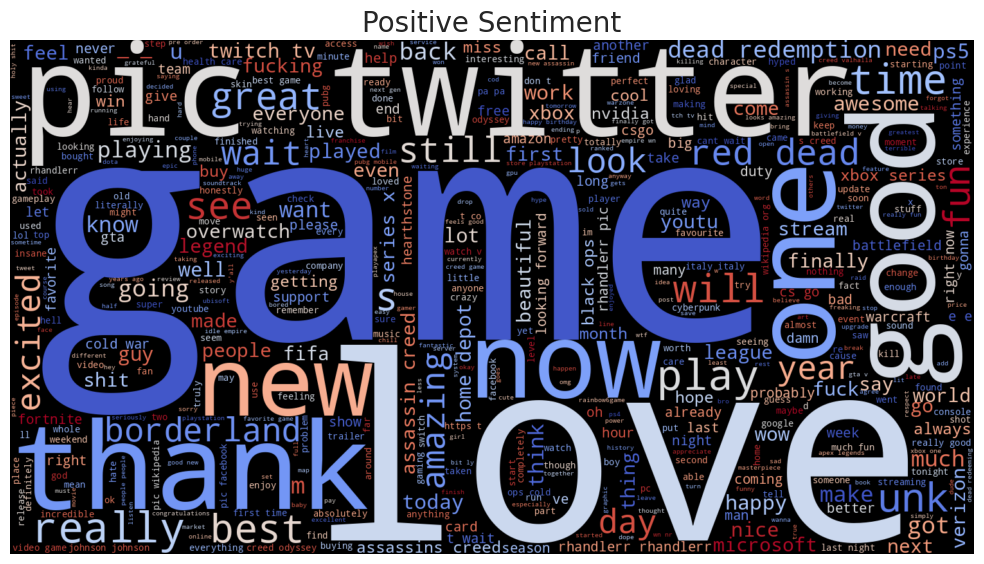

In [23]:
# show Positive word cloud
positive_words = ' '.join(df_en[df_en['sentiment'] == 2]['text'])

generate_wordcloud(positive_words, title= 'Positive Sentiment')

### Negative Words

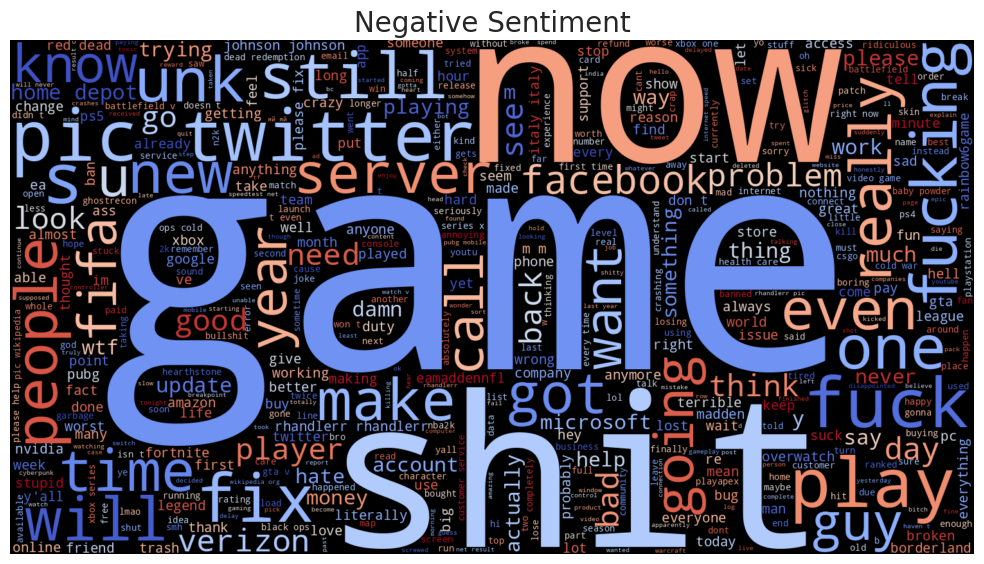

In [24]:
# show Negative word cloud
Negative_words = ' '.join(df_en[df_en['sentiment'] == 0]['text'])

generate_wordcloud(Negative_words, title= 'Negative Sentiment')

### Neutral Words

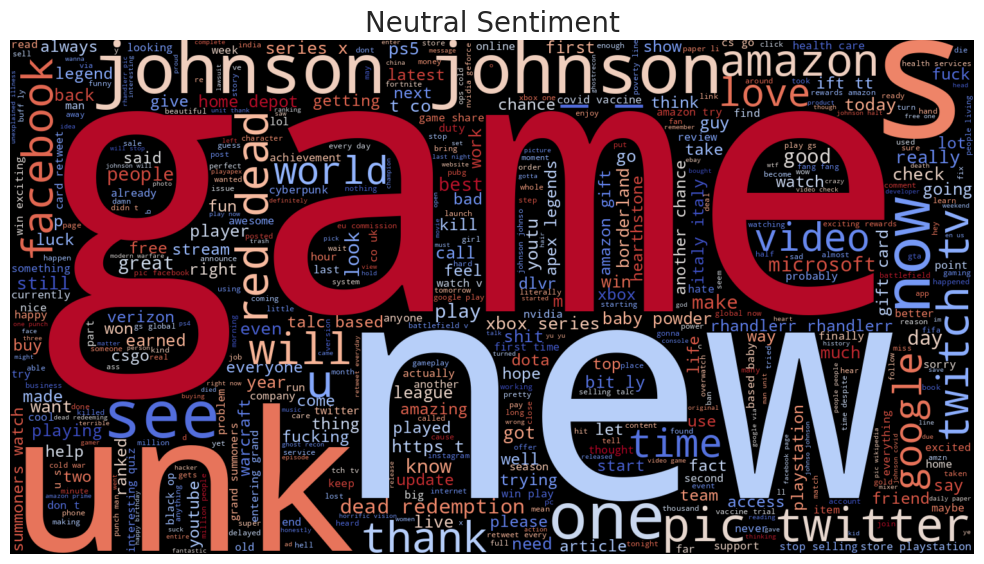

In [25]:
# # show Negative word cloud
Neutral = ' '.join(df_en[df_en['sentiment'] == 1]['text'])

generate_wordcloud(Neutral, title= 'Neutral Sentiment')

### Bar Chart

In [26]:
def show_top_words(input, type):
    words = input.split()
    top_words = pd.DataFrame(Counter(words).most_common(25), columns=['Term', 'Count'])
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(12, 10))
    sns.barplot(x='Count', y='Term', data=top_words, palette='coolwarm')
    plt.title(f"Top 25 Words in {type} Reviews")
    plt.xlabel("Occurrences")
    plt.ylabel("Terms")
    plt.tight_layout()
    plt.show()

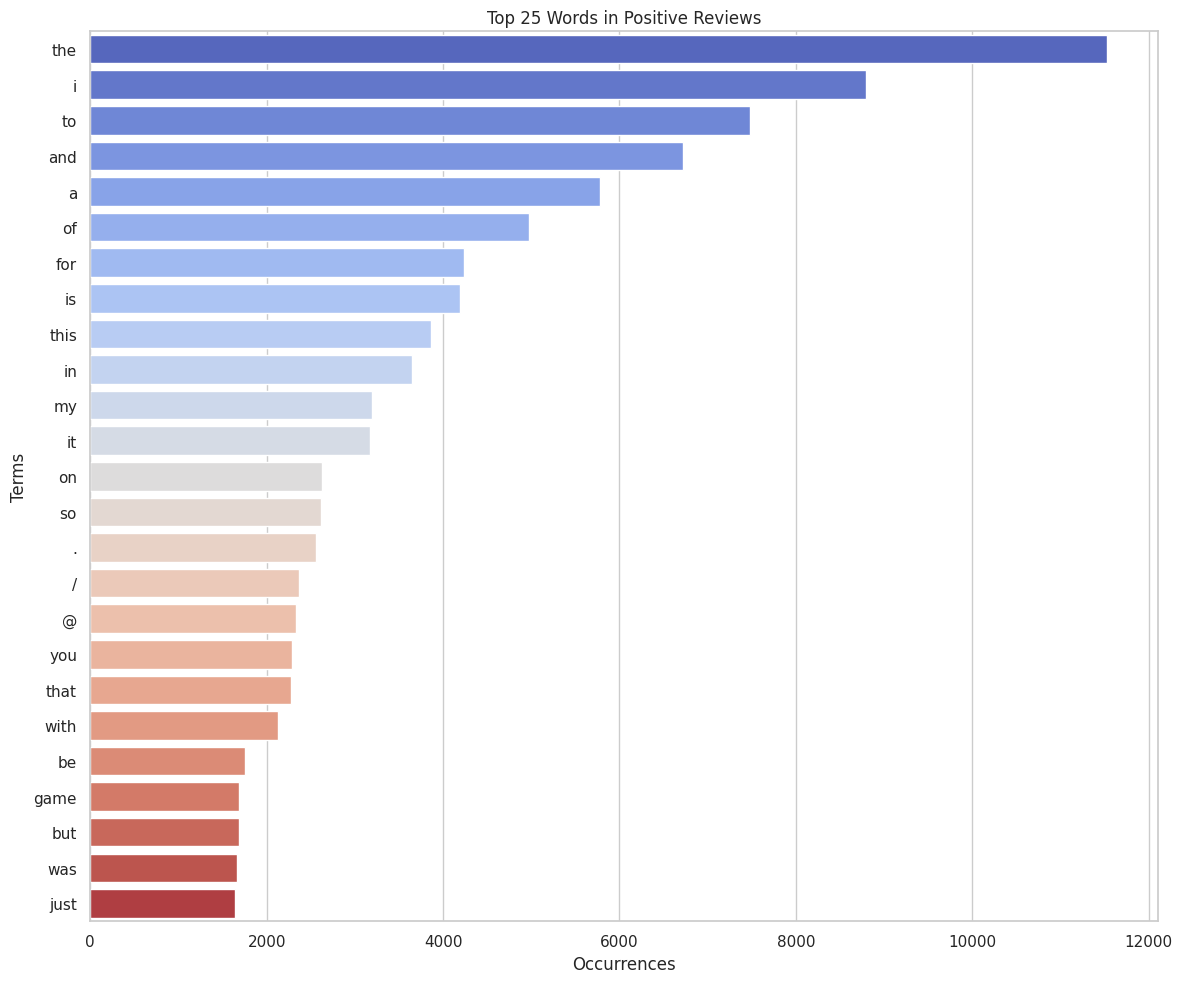

In [27]:
# show frequancy of positive words
show_top_words(positive_words, "Positive")

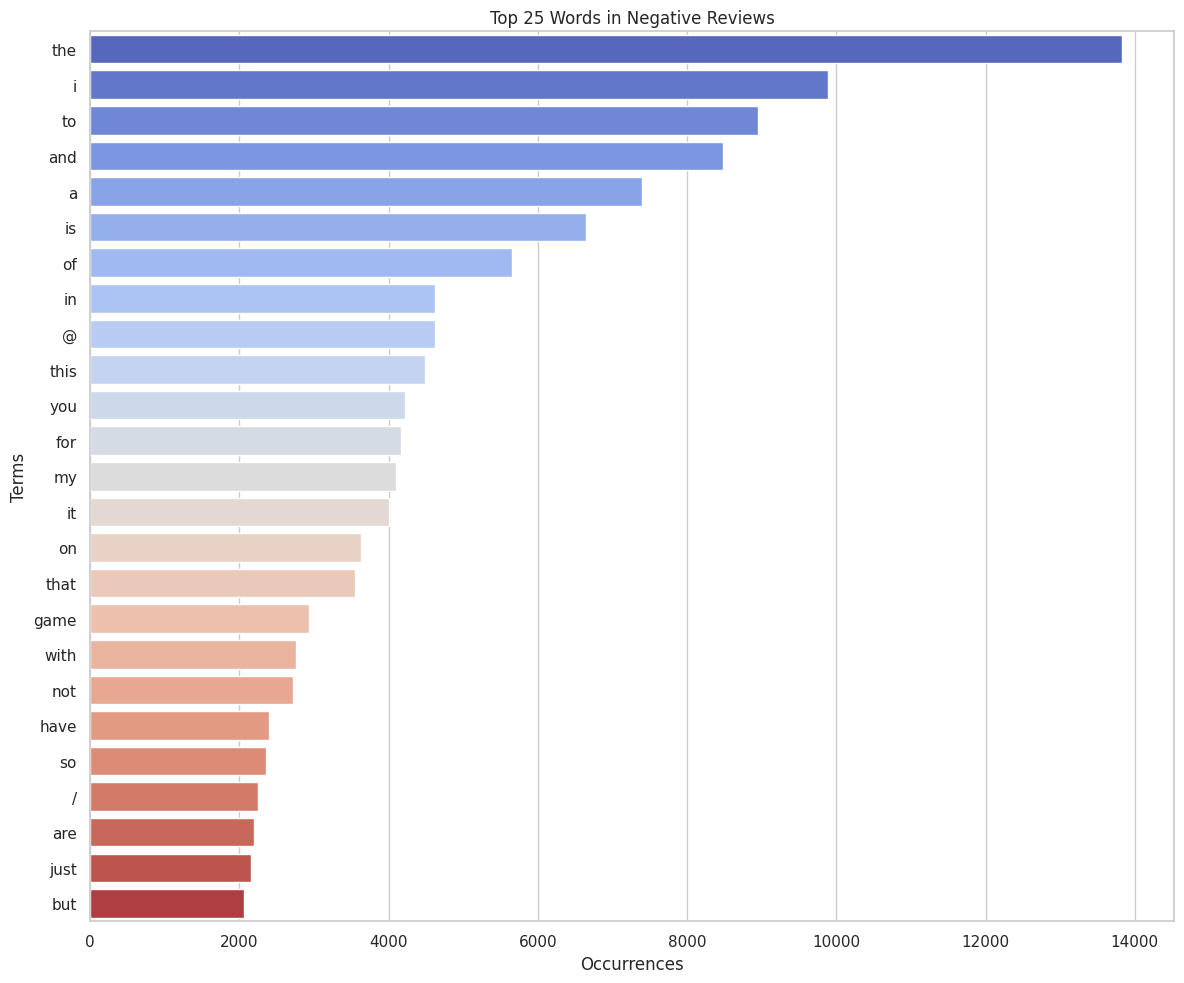

In [28]:
show_top_words(Negative_words, "Negative")

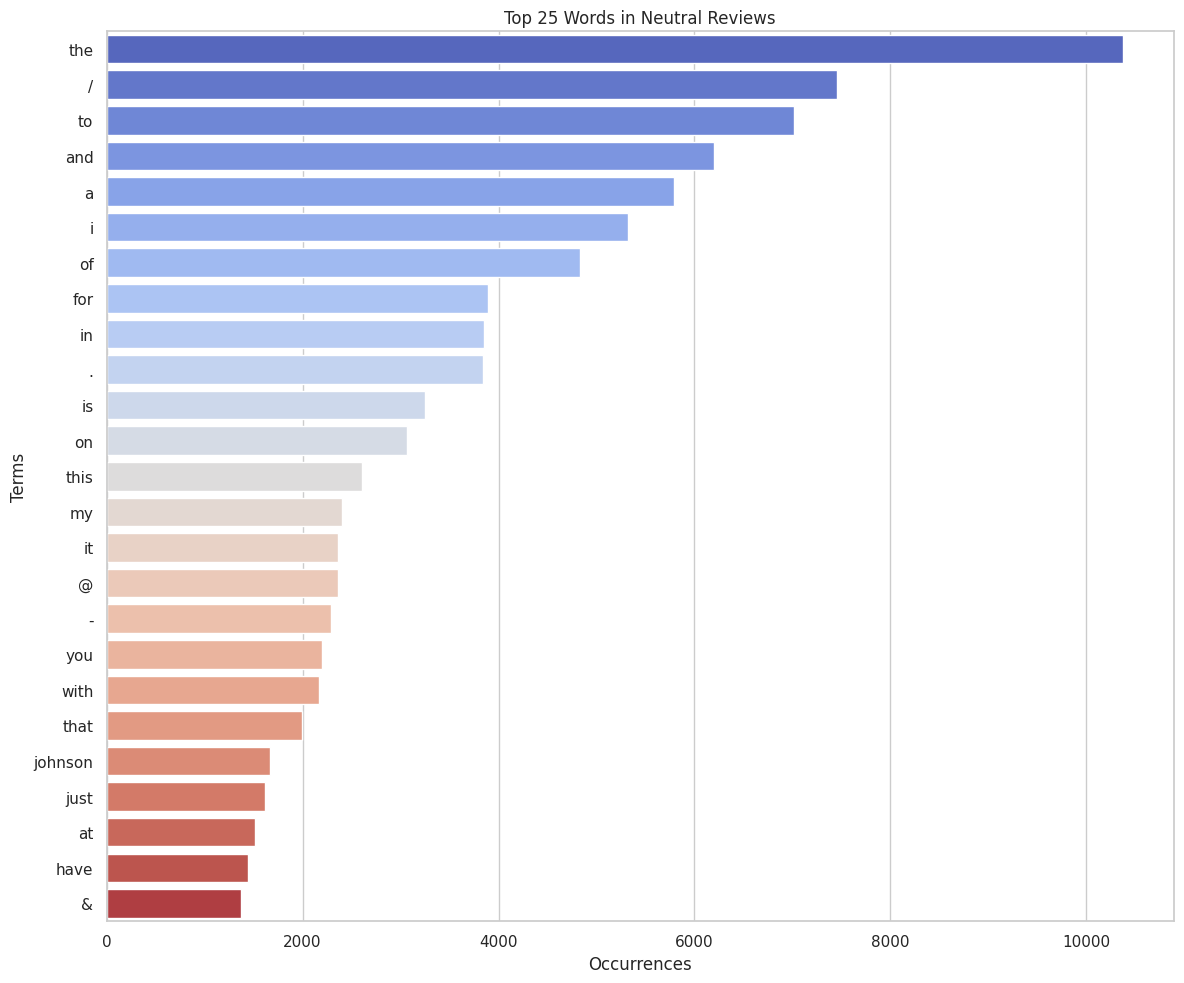

In [29]:
show_top_words(Neutral, "Neutral")

## 8. Chart Pie for Polarity

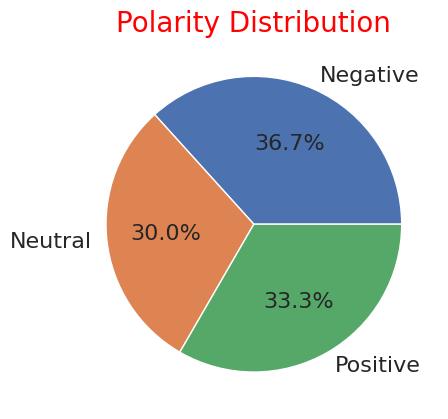

In [30]:
# Pie chart for polarity
count_pol = df_en['sentiment'].value_counts().sort_index()
index = ['Negative', 'Neutral', 'Positive']
plt.pie(
    count_pol,
    labels= index,
    autopct='%1.1f%%',
    textprops={'fontsize': 16}
)

plt.title('Polarity Distribution', color= 'red', fontsize= 20)
plt.show()

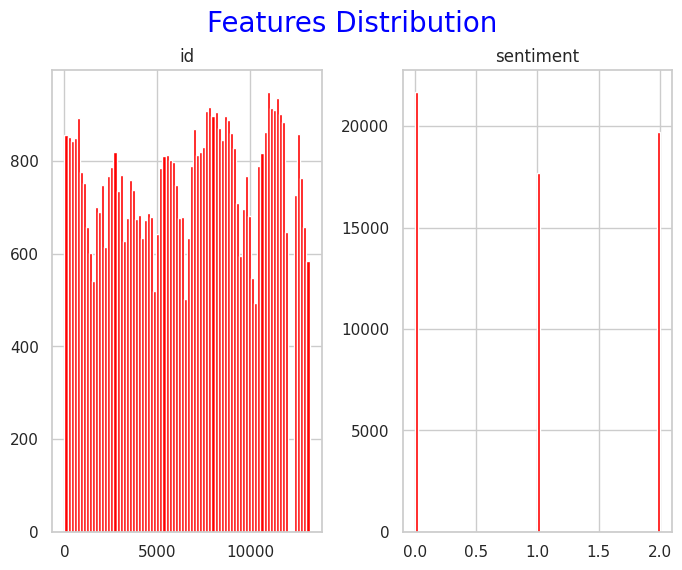

In [31]:
# historgram 
df_en.hist(figsize=(8,6), bins=80, color='red')
plt.suptitle("Features Distribution", fontsize= 20, color='blue')

plt.show()

### Save Dataset After Processing

<details>
<summary>Click Here</summary> </br>

```python
df.to_csv("Cleaned_data.csv", index= False)

## 9. Prepare Data for Model

In [32]:
# Arabic: Negative = 0, Positive = 2 (same as english labels) -> no neutral in arabic
df_ar["sentiment"] = df_ar["Polarity"].map({
    "Negative": 0,
    "Positive": 2
})

df_ar["text"] = df_ar["content"]
df_ar["entity"] = "review"     # no entity in arabic data
df_ar["lang"] = "ar"

df_ar = df_ar[["entity", "text", "sentiment", "lang"]]
df_ar = df_ar.dropna()

df_ar.head()

,entity,text,sentiment,lang
0,review,النعال المريحة: أرتدي هذه النعال كثيرًا!فهي دا...,2,ar
1,review,منتج جميل ، خدمة سيئة: لقد اشتريت زوجًا من الن...,2,ar
2,review,جيد للأشياء الصغيرة: هذا يعمل بشكل جيد لالتقاط...,2,ar
3,review,واهية للغاية: flimsyif للغاية ، فأنت تشتريه ، ...,0,ar
4,review,Pop for Girls and Girly Boys ، والأشخاص الذين ...,2,ar


## 10. Data Cleaning and Type Handling

In [33]:
# English: keep game as entity (sentiment is about the game)
df_en["entity"] = df_en["game"]
df_en["lang"] = "en"

df_en = df_en[["entity", "text", "sentiment", "lang"]]
df_en = df_en.dropna()

df_en.head()

,entity,text,sentiment,lang
0,Borderlands,im getting on borderlands and i will murder yo...,2,en
1,Borderlands,i am coming to the borders and i will kill you...,2,en
2,Borderlands,im getting on borderlands and i will kill you ...,2,en
3,Borderlands,im coming on borderlands and i will murder you...,2,en
4,Borderlands,im getting on borderlands 2 and i will murder ...,2,en


In [34]:
# merge between dataset
df_all = pd.concat([df_ar, df_en], axis=0).reset_index(drop=True)

# check labels after merge (must be 0,1,2 with same meaning for both langs)
print(df_all.groupby(['lang', 'sentiment']).size())

lang  sentiment
ar    0            39818
      2            40174
en    0            21698
      1            17708
      2            19713
dtype: int64


### Clean types (fix for: TypeError: TextInputSequence must be str)

In [35]:
# check types before tokenizer (tokenizer accepts str only)
print("Types of text:")
print(df_all['text'].map(type).value_counts())

print("\nTypes of entity:")
print(df_all['entity'].map(type).value_counts())

print("\nNull values:")
print(df_all.isna().sum())

Types of text:
text
<class 'str'>    139111
Name: count, dtype: int64

Types of entity:
entity
<class 'str'>    139111
Name: count, dtype: int64

Null values:
entity       0
text         0
sentiment    0
lang         0
dtype: int64


In [36]:
# force everything to clean string / int
df_all = df_all.dropna(subset=['text', 'entity', 'sentiment'])

for col in ['entity', 'text']:
    df_all[col] = df_all[col].astype(str).str.strip()

df_all['sentiment'] = df_all['sentiment'].astype(int)

# drop empty text (after cleaning links and mentions some tweets become empty)
df_all = df_all[df_all['text'].str.len() > 0]
df_all = df_all[df_all['text'].str.lower() != 'nan']
df_all = df_all[df_all['entity'].str.lower() != 'nan']

# check again
print(df_all['text'].map(type).value_counts())
print(df_all['entity'].map(type).value_counts())
print(f'Shape after cleaning: {df_all.shape}')

text
<class 'str'>    138946
Name: count, dtype: int64
entity
<class 'str'>    138946
Name: count, dtype: int64
Shape after cleaning: (138946, 4)


### Remove Duplicates and Data Splitting

In [37]:
# drop duplicated by text only (to avoid leakage between train and val)
print(f'Duplicated text: {df_all.duplicated(subset="text").sum()}')

df_all = df_all.drop_duplicates(subset="text")
df_all = df_all.sample(frac=1, random_state=42).reset_index(drop=True)

print(df_all.groupby(['lang', 'sentiment']).size())

Duplicated text: 2291
lang  sentiment
ar    0            39818
      2            40174
en    0            20982
      1            16855
      2            18826
dtype: int64


In [38]:
# stratified split: 80% train / 10% val / 10% test
strat = df_all['lang'] + '_' + df_all['sentiment'].astype(str)

train_df, temp_df = train_test_split(
    df_all, test_size=0.2, random_state=42, stratify=strat
)

strat_temp = temp_df['lang'] + '_' + temp_df['sentiment'].astype(str)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=strat_temp
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f'Train shape: {train_df.shape}')
print(f'Val shape: {val_df.shape}')
print(f'Test shape: {test_df.shape}')

Train shape: (109324, 4)
Val shape: (13665, 4)
Test shape: (13666, 4)


## 11. Tokenization

In [39]:
# Convert dataframe to Hugging face dataset
def to_hf(df):
    return Dataset.from_pandas(
        df[['entity', 'text', 'sentiment']].rename(columns={'sentiment':'label'}),
        preserve_index=False
    )

train_data = to_hf(train_df)
val_data = to_hf(val_df)
test_data = to_hf(test_df)

# model name (tokenizer MUST be the same as the model)
model_name = "xlm-roberta-base"
# model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"   # try this one too

tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [40]:
# tokenizer function (entity + text as pair), padding is done later by the collator
def tokenize_function(example):
    # str() again as a safety, to be sure that all values are string
    entity = [str(x) for x in example["entity"]]
    text = [str(x) for x in example["text"]]

    return tokenizer(
        entity,
        text,
        truncation="only_second",
        max_length=128
    )

token_train = train_data.map(tokenize_function, batched= True)
token_val = val_data.map(tokenize_function, batched= True)
token_test = test_data.map(tokenize_function, batched= True)

Map:   0%|          | 0/109324 [00:00<?, ? examples/s]

Map:   0%|          | 0/13665 [00:00<?, ? examples/s]

Map:   0%|          | 0/13666 [00:00<?, ? examples/s]

In [41]:
print(token_train[0]['input_ids'][:20])
print(tokenizer.decode(token_train[0]['input_ids']))
print('-'*60)
print(token_val[0]['input_ids'][:20])
print(tokenizer.decode(token_val[0]['input_ids']))

[0, 8347, 2, 183825, 86586, 38, 12, 94991, 39287, 3630, 73831, 13, 9464, 39391, 43731, 183825, 703, 258, 86586, 703]
<s> review</s> منتج ممتاز!: يعد Palmone Zire 72 Hard Case منتجًا ممتازًا - إنه يوفر حماية ممتازة لطيار النخيل الخاص بي ، وسهلة الفتح وله "باب" أنيق في الخلف يمكّنني من استخدام الكاميرا دون إزالةطيار النخيل من القضية!</s>
------------------------------------------------------------
[0, 227593, 2, 1660, 456, 9, 80383, 297, 2856, 5036, 678, 903, 17997, 2174, 9, 10869, 9, 9774, 13, 9]
<s> Nvidia</s> just re-installed them now with this guide if-not-true-then-false.com/2015/fedora-nv... and... and, he is still active from 2</s>


## 12. Model + Training

In [42]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [43]:
training_args = TrainingArguments(
    output_dir="./xlmr_sentiment",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,

    num_train_epochs=5,

    weight_decay=0.01,
    warmup_ratio=0.1,
    lr_scheduler_type="linear",

    logging_dir="./logs",
    logging_steps=100,

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    save_total_limit=1,

    fp16=True,
    report_to="none",
)

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


In [44]:
labels = train_data["label"]

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = torch.tensor(class_weights, dtype=torch.float)
print(class_weights)

tensor([0.7492, 2.7026, 0.7721])


## 13. Class Weight Calculation

In [45]:
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")

        outputs = model(**inputs)
        logits = outputs.logits

        loss_fct = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_fct(logits, labels)

        return (loss, outputs) if return_outputs else loss

In [46]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="weighted")
    }

## 14. Weighted Trainer and Evaluation Metrics

### Model Training

In [47]:
# Traininer
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=token_train,
    eval_dataset=token_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.407464,0.374874,0.868203,0.869179
2,0.264233,0.253911,0.893011,0.894700
3,0.178835,0.221706,0.915404,0.915680
4,0.128164,0.218336,0.928357,0.928379
5,0.092827,0.227899,0.932894,0.932895


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=8545, training_loss=0.26277810141941205, metrics={'train_runtime': 9375.0129, 'train_samples_per_second': 58.306, 'train_steps_per_second': 0.911, 'total_flos': 3.595576409961984e+16, 'train_loss': 0.26277810141941205, 'epoch': 5.0})

### Evaluation

Perdiction on Test data


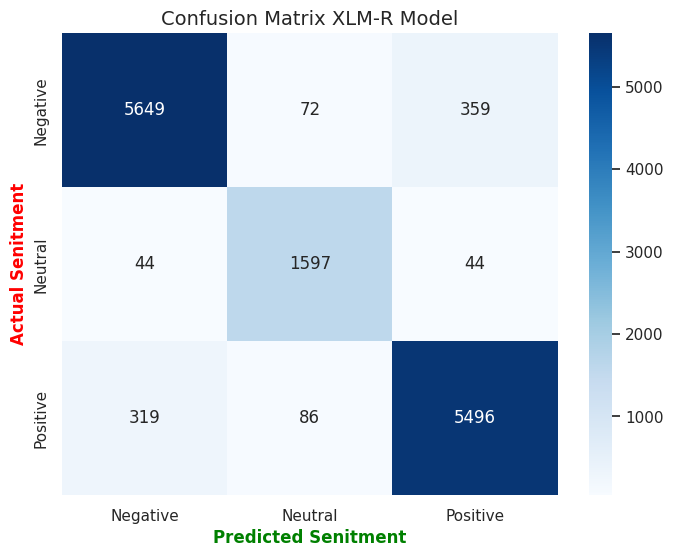

In [48]:
print("Perdiction on Test data")
preds = trainer.predict(token_test)

y_preds = np.argmax(preds.predictions, axis=1)
y_true = preds.label_ids

CLASSESNAME = ['Negative', 'Neutral', 'Positive']

# confuction matrix
cm = confusion_matrix(y_true, y_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt= 'd', cmap='Blues', cbar=True,
           xticklabels=CLASSESNAME, yticklabels=CLASSESNAME)
plt.xlabel('Predicted Senitment', fontsize=12, fontweight='bold', color='green')
plt.ylabel('Actual Senitment', fontsize=12, fontweight='bold', color='red')
plt.title("Confusion Matrix XLM-R Model", fontsize=14)

plt.show()

## 15. Confusion Matrix and Classification Report

In [49]:
# Print Report
print("Classification Report:\n")
print(classification_report(y_true, y_preds, target_names=CLASSESNAME))

Classification Report:

              precision    recall  f1-score   support

    Negative       0.94      0.93      0.93      6080
     Neutral       0.91      0.95      0.93      1685
    Positive       0.93      0.93      0.93      5901

    accuracy                           0.93     13666
   macro avg       0.93      0.94      0.93     13666
weighted avg       0.93      0.93      0.93     13666



## 16. Language-Specific Evaluation

In [50]:
# Report for each language (to know where the model is weak)
for lang in ['ar', 'en']:
    mask = (test_df['lang'] == lang).values
    print(f"===== {lang.upper()} =====")
    print(f"Accuracy: {accuracy_score(y_true[mask], y_preds[mask]):.4f}")
    print(classification_report(
        y_true[mask], y_preds[mask],
        labels=[0, 1, 2], target_names=CLASSESNAME, zero_division=0
    ))

===== AR =====
Accuracy: 0.9353
              precision    recall  f1-score   support

    Negative       0.94      0.93      0.93      3982
     Neutral       0.00      0.00      0.00         0
    Positive       0.93      0.94      0.94      4018

    accuracy                           0.94      8000
   macro avg       0.62      0.62      0.62      8000
weighted avg       0.94      0.94      0.94      8000

===== EN =====
Accuracy: 0.9283
              precision    recall  f1-score   support

    Negative       0.94      0.93      0.93      2098
     Neutral       0.91      0.95      0.93      1685
    Positive       0.94      0.91      0.92      1883

    accuracy                           0.93      5666
   macro avg       0.93      0.93      0.93      5666
weighted avg       0.93      0.93      0.93      5666



## 17. Error Analysis

In [51]:
# look at some wrong predictions
wrong = test_df.copy()
wrong['pred'] = y_preds
wrong = wrong[wrong['pred'] != wrong['sentiment']]

wrong.sample(10, random_state=42)[['lang', 'entity', 'text', 'sentiment', 'pred']]

,lang,entity,text,sentiment,pred
4867,en,Dota2,dota2 is updated.,0,2
12866,en,Microsoft,for donald trump demanding he get cut short of...,0,1
315,ar,review,لا يحتوي Blu-ray على ترجمات أو تسميات توضيحية ...,0,2
12623,ar,review,الشريط الوحيد للكلاب: نحن نولد من Deberman Pin...,2,0
4439,en,Borderlands,everywhere there are huge improvements in the ...,2,0
916,ar,review,Super Poppy مع بعض الأجزاء الجيدة: Dead Poetch...,2,0
3213,ar,review,كتاب رائع ، كتاب رائع لقراءة مرارًا وتكرارًا: ...,0,2
2498,en,HomeDepot,"lou, do you make an amazing homemade sweets de...",0,2
8254,ar,review,مراجعة الأزياء: أمرت زي Jedi Knight Qui-Gon Ji...,0,2
13018,en,Borderlands,"eli roth is making a movie about the game,.. b...",2,1


## 18. Training History Visualization

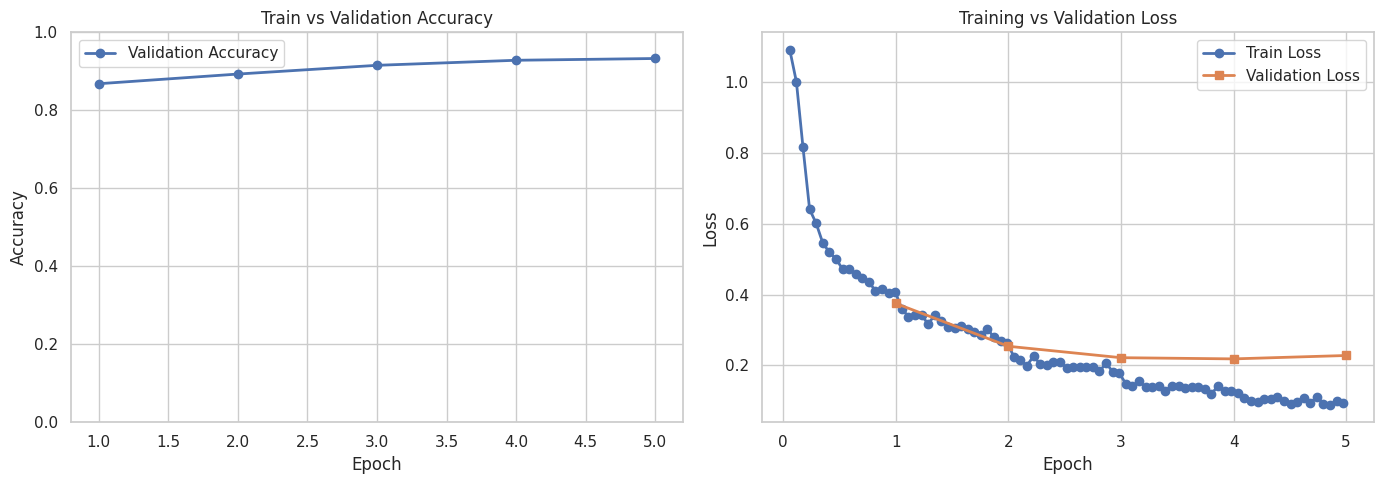


Final Train Accuracy Calculation:


Final Train Accuracy: 0.9791


In [52]:
# Get history from trainer
history = trainer.state.log_history

# Split logs
train_logs = [log for log in history if 'loss' in log and 'eval_loss' not in log]
eval_logs  = [log for log in history if 'eval_loss' in log]


# Training Loss
train_epochs = [log['epoch'] for log in train_logs]
train_losses = [log['loss'] for log in train_logs]

# Validation Metrics
eval_epochs = [log['epoch'] for log in eval_logs]
eval_losses = [log['eval_loss'] for log in eval_logs]
val_accuracies = [log.get('eval_accuracy') for log in eval_logs]

# Try to get Train Accuracy (if exists)
train_acc_logs = [log for log in history if 'accuracy' in log and 'eval_accuracy' not in log]

if len(train_acc_logs) > 0:
    train_acc_epochs = [log['epoch'] for log in train_acc_logs]
    train_accuracies = [log['accuracy'] for log in train_acc_logs]
else:
    train_acc_epochs = []
    train_accuracies = []


# Plot
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.plot(eval_epochs, val_accuracies, marker='o', linewidth=2, label='Validation Accuracy')
if len(train_accuracies) > 0:
    plt.plot(train_acc_epochs, train_accuracies, marker='s', linewidth=2, label='Train Accuracy')

plt.title('Train vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0,1])
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)

plt.plot(train_epochs, train_losses, marker='o', linewidth=2, label='Train Loss')
plt.plot(eval_epochs, eval_losses, marker='s', linewidth=2, label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# OPTIONAL: Calculate final Train Accuracy manually
print("\nFinal Train Accuracy Calculation:")

train_preds = trainer.predict(token_train)

y_train_pred = np.argmax(train_preds.predictions, axis=1)
y_train_true = train_preds.label_ids

train_acc = accuracy_score(y_train_true, y_train_pred)
print(f"Final Train Accuracy: {train_acc:.4f}")

### Validation and Test Accuracy

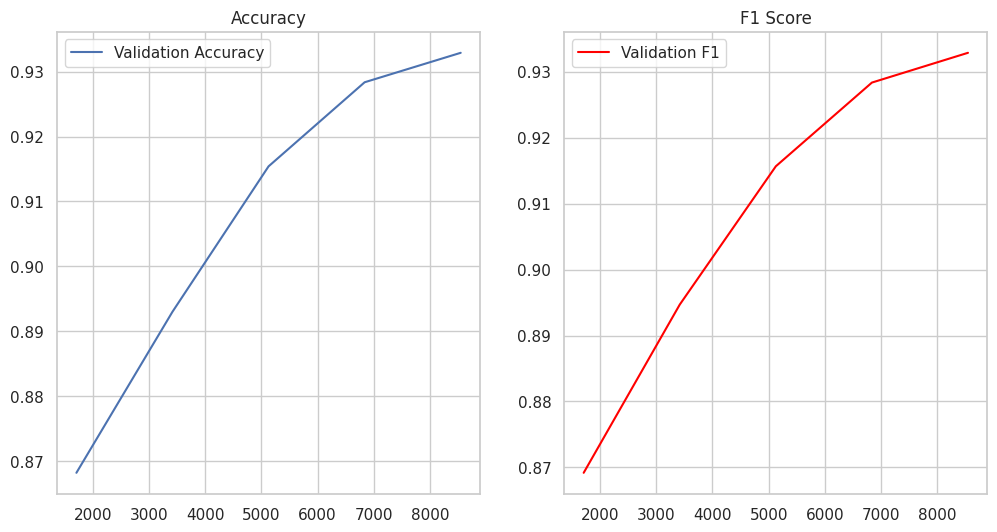

In [53]:
history = trainer.state.log_history

train_acc = []
val_acc = []
train_f1 = []
val_f1 = []
steps = []

for log in history:
    if "eval_accuracy" in log:
        val_acc.append(log["eval_accuracy"])
        val_f1.append(log.get("eval_f1"))
        steps.append(log["step"])

    if "loss" in log and "eval_loss" not in log:
        if "eval_f1" in log:
            train_f1.append(log["eval_f1"])
        if "eval_accuracy" in log:
            train_acc.append(log["eval_accuracy"])

# Accuracy plot
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.plot(steps, val_acc, label="Validation Accuracy")
plt.title("Accuracy")
plt.legend()

# F1 plot
plt.subplot(1,2,2)
plt.plot(steps, val_f1, label="Validation F1", color="red")
plt.title("F1 Score")
plt.legend()
plt.show()

In [54]:
print("\nFinal Val Accuracy Calculation:")

val_preds = trainer.predict(token_val)

y_val_pred = np.argmax(val_preds.predictions, axis=1)
y_val_true = val_preds.label_ids

val_acc = accuracy_score(y_val_true, y_val_pred)
print(f"Final Val Accuracy: {val_acc:.4f}")

test_acc = accuracy_score(y_true, y_preds)
print(f"Final Test Accuracy: {test_acc:.4f}")


Final Val Accuracy Calculation:


Final Val Accuracy: 0.9329
Final Test Accuracy: 0.9324


### Save + Try the model

In [55]:
trainer.save_model("./final_xlmr_model")
tokenizer.save_pretrained("./final_xlmr_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./final_xlmr_model/tokenizer_config.json',
 './final_xlmr_model/tokenizer.json')

## 19. Sentiment Prediction

In [56]:
import torch
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
model.eval()

CLASS_NAMES = ['Negative', 'Neutral', 'Positive']

# the model was trained on (entity, text) pairs
# entity = game name for english tweets, "review" for arabic (use it if you dont know the entity)
def predict_sentiment(text, entity="review"):
    inputs = tokenizer(str(entity), str(text),
                       padding="max_length",
                       truncation="only_second",
                       max_length=128,
                       return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model(**inputs)
    probs = F.softmax(outputs.logits, dim=-1)

    predicted_class_id = torch.argmax(probs, dim=-1).item()
    confidence = probs[0][predicted_class_id].item()

    predicted_label = CLASS_NAMES[predicted_class_id]

    return predicted_label, confidence

test_sentences = [
    # Positive
    "I absolutely love this new update, the game looks amazing!",  # Positive (2)
    "صباحكم فل يا خواتي",  # Positive (2)
    "The game is really fun and I enjoy playing it with my friends.",  # Positive (2)
    "This product exceeded my expectations, I am very happy with it.",  # Positive (2)
    "I had a wonderful day and everything went perfectly.",  # Positive (2)
    "I love how beautiful this place looks!",  # Positive (2)
    "El game da gamed awy w ana mabsoot gedan beh.",  # Positive (2)
    "Ana far7an awy en el youm kan gameel keda.",  # Positive (2)

    # Negative
    "This is the worst experience ever, my account got banned for no reason.",  # Negative (0)
    "I hate this update, it made the game much worse.",  # Negative (0)
    "The customer service was terrible and nobody helped me.",  # Negative (0)
    "I regret buying this product, it was a complete waste of money.",  # Negative (0)
    "I am so disappointed with the quality of this product.",  # Negative (0)
    "The game keeps crashing and I cannot play anymore.",  # Negative (0)
    "El game da we7esh awy w mesh 3aref al3ab feeh.",  # Negative (0)
    "Ana za3lan gedan men el service el saye2 da.",  # Negative (0)

    # Neutral
    "I played the game for 2 hours today.",  # Neutral (1)
    "It's okay, not the best but I can play it when I'm bored.",  # Neutral (1)
    "I read an article about space exploration this morning.",  # Neutral (1)
    "The color of this shirt is light blue.",  # Neutral (1)
    "I am going to the supermarket to buy some milk.",  # Neutral (1)
    "The game was released last year.",  # Neutral (1)
    "I played three matches yesterday.",  # Neutral (1)
    "El youm ro7t el gam3a w rag3t el beet.",  # Neutral (1),

    # Mixed Arabic-English 
    "اللعبة دي amazing بجد ومش قادر أبطل ألعبها.",  # Positive (2)
    "أنا مبسوط جداً من ال new update، كل حاجة بقت أحسن.",  # Positive (2)
    "الـ customer service كانوا helpful جداً وحلوا المشكلة بسرعة.",  # Positive (2)
    "الفيلم كان boring جداً ومقدرتش أكمله للآخر.",  # Negative (0)
    "أنا disappointed جداً من ال quality بتاعة المنتج ده.",  # Negative (0)
    "الـ application بيعمل crash كل شوية ومش عارف أستخدمه.",  # Negative (0)
    "أنا عملت download للعبة امبارح وجربتها شوية.",  # Neutral (1)
    "عندي meeting الساعة 5 وبعدها هروح البيت.",  # Neutral (1)
    "اشتريت new laptop امبارح ولسه بجرب فيه البرامج.",  # Neutral (1)
    "الـ update نزل النهارده ولسه مش عارف إيه الجديد فيه.",  # Neutral (1)
    "الـ food كان delicious جداً والمكان كان جميل.",  # Positive (2)
    "التجربة كانت terrible والـ staff مش متعاون خالص.",  # Negative (0)
]

print("--- Testing the XLM-R Model ---\n")
for sentence in test_sentences:
    label, conf = predict_sentiment(sentence)
    print(f"Tweet: '{sentence}'")
    print(f"Prediction: [{label}] (Confidence: {conf*100:.2f}%)\n")
    print("-" * 50)

--- Testing the XLM-R Model ---

Tweet: 'I absolutely love this new update, the game looks amazing!'
Prediction: [Positive] (Confidence: 93.80%)

--------------------------------------------------
Tweet: 'صباحكم فل يا خواتي'
Prediction: [Positive] (Confidence: 96.26%)

--------------------------------------------------
Tweet: 'The game is really fun and I enjoy playing it with my friends.'
Prediction: [Positive] (Confidence: 99.93%)

--------------------------------------------------
Tweet: 'This product exceeded my expectations, I am very happy with it.'
Prediction: [Positive] (Confidence: 99.89%)

--------------------------------------------------
Tweet: 'I had a wonderful day and everything went perfectly.'
Prediction: [Neutral] (Confidence: 98.92%)

--------------------------------------------------
Tweet: 'I love how beautiful this place looks!'
Prediction: [Positive] (Confidence: 99.89%)

--------------------------------------------------
Tweet: 'El game da gamed awy w ana mabsoo

## 20. Advanced Sentiment Prediction

In [57]:
def advanced_predict_sentiment(text, entity="review", strict_threshold=0.75):
    inputs = tokenizer(str(entity), str(text), padding="max_length", truncation="only_second", max_length=128, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)

    probs = F.softmax(outputs.logits, dim=-1)[0]
    prob_neg = probs[0].item()
    prob_neu = probs[1].item()
    prob_pos = probs[2].item()

    predicted_class_id = torch.argmax(probs, dim=-1).item()
    base_label = CLASS_NAMES[predicted_class_id]
    base_confidence = probs[predicted_class_id].item()

    final_label = base_label
    reason = "Confident in his decision (High Confidence)"

    if base_label in ['Positive', 'Negative'] and base_confidence < strict_threshold:
        final_label = 'Neutral'
        reason = f"It was switched to neutral because the model ({base_confidence*100:.1f}%)Less than the minimum ({strict_threshold*100}%)"

    elif abs(prob_pos - prob_neg) < 0.20 and prob_neu < 0.40:
         final_label = 'Neutral'
         reason = "It was switched to neutral (Mixed Sentiment)"

    return final_label, base_confidence, (prob_neg, prob_neu, prob_pos), reason

print("--- Testing the ADVANCED XLM-R Model ---\n")
for sentence in test_sentences:
    label, conf, all_probs, reason = advanced_predict_sentiment(sentence, strict_threshold=0.75)

    print(f"📝 Twitter: '{sentence}'")
    print(f"🎯 final predict: [{label}]")
    print(f"📊 Probability: (Positive: {all_probs[2]*100:.1f}% | Neutral: {all_probs[1]*100:.1f}% | Negative: {all_probs[0]*100:.1f}%)")
    print(f"💡 Causes: {reason}\n")
    print("-" * 60)

--- Testing the ADVANCED XLM-R Model ---

📝 Twitter: 'I absolutely love this new update, the game looks amazing!'
🎯 final predict: [Positive]
📊 Probability: (Positive: 93.8% | Neutral: 4.4% | Negative: 1.8%)
💡 Causes: Confident in his decision (High Confidence)

------------------------------------------------------------
📝 Twitter: 'صباحكم فل يا خواتي'
🎯 final predict: [Positive]
📊 Probability: (Positive: 96.3% | Neutral: 0.0% | Negative: 3.7%)
💡 Causes: Confident in his decision (High Confidence)

------------------------------------------------------------
📝 Twitter: 'The game is really fun and I enjoy playing it with my friends.'
🎯 final predict: [Positive]
📊 Probability: (Positive: 99.9% | Neutral: 0.0% | Negative: 0.1%)
💡 Causes: Confident in his decision (High Confidence)

------------------------------------------------------------
📝 Twitter: 'This product exceeded my expectations, I am very happy with it.'
🎯 final predict: [Positive]
📊 Probability: (Positive: 99.9% | Neutral: 